In [ ]:
x   import sys

print(sys.executable)


c:\Users\ompis\OneDrive\Desktop\credit risk scoring model\.venv\Scripts\python.exe


# Credit Risk Scoring Model

## 1. Dataset Loading

This project develops a machine learning-based credit risk scoring system to predict the likelihood of loan default using applicant financial, demographic, employment, and credit-related information.

In [2]:
import pandas as pd
import numpy as np
import matplotlib
import seaborn as sns
import sklearn

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("All libraries imported successfully!")

Pandas: 3.0.6
NumPy: 2.5.3
Scikit-learn: 1.9.1
All libraries imported successfully!


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully!")


Libraries imported successfully!


In [4]:
import pandas as pd
import numpy as np
import matplotlib
import seaborn as sns
import sklearn

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("All libraries imported successfully!")

Pandas: 3.0.6
NumPy: 2.5.3
Scikit-learn: 1.9.1
All libraries imported successfully!


In [5]:
DATA_PATH = Path("../data/raw/credit_risk_dataset.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 32581
Columns: 12


In [6]:
DATA_PATH = Path("../data/raw/credit_risk_dataset.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 32581
Columns: 12


In [7]:
from pathlib import Path
import pandas as pd

DATA_PATH = Path("../data/raw/credit_risk_dataset.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 32581
Columns: 12


In [8]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [9]:
df.tail()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
32576,57,53000,MORTGAGE,1.0,PERSONAL,C,5800,13.16,0,0.11,N,30
32577,54,120000,MORTGAGE,4.0,PERSONAL,A,17625,7.49,0,0.15,N,19
32578,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,35000,10.99,1,0.46,N,28
32579,56,150000,MORTGAGE,5.0,PERSONAL,B,15000,11.48,0,0.10,N,26
32580,66,42000,RENT,2.0,MEDICAL,B,6475,9.99,0,0.15,N,30


In [10]:
df.shape


(32581, 12)

In [11]:
df.columns

Index(['person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_default_on_file', 'cb_person_cred_hist_length'],
      dtype='str')

## 2. Dataset Structure and Initial Audit


In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.0 MB


In [13]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [14]:
df.describe(include="object")

,person_home_ownership,loan_intent,loan_grade,cb_person_default_on_file
count,32581,32581,32581,32581
unique,4,6,7,2
top,RENT,EDUCATION,A,N
freq,16446,6453,10777,26836


## 3. Missing Value Analysis


In [15]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

missing[missing["Missing Count"] > 0]

,Missing Count,Missing Percentage
person_emp_length,895,2.75
loan_int_rate,3116,9.56


In [16]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 165


## 4. Target Variable Analysis

In [17]:
df["loan_status"].value_counts()

loan_status
0    25473
1     7108
Name: count, dtype: int64

In [18]:
df["loan_status"].value_counts(normalize=True) * 100

loan_status
0    78.183604
1    21.816396
Name: proportion, dtype: float64

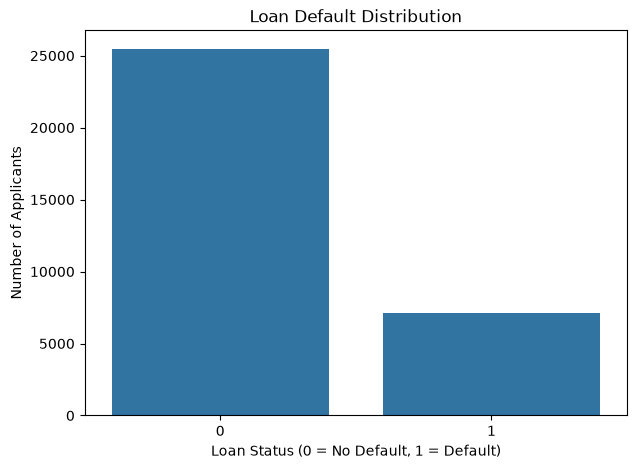

In [19]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="loan_status")

plt.title("Loan Default Distribution")
plt.xlabel("Loan Status (0 = No Default, 1 = Default)")
plt.ylabel("Number of Applicants")

plt.show()

## 5. Data Cleaning

In [20]:

df_clean = df.copy()

print("Original dataset shape:", df_clean.shape)

Original dataset shape: (32581, 12)


In [21]:
duplicate_count = df_clean.duplicated().sum()

print("Duplicate rows found:", duplicate_count)

Duplicate rows found: 165


In [22]:
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Dataset shape after removing duplicates:", df_clean.shape)

Dataset shape after removing duplicates: (32416, 12)


In [23]:
print("Age below 18:", (df_clean["person_age"] < 18).sum())
print("Age above 100:", (df_clean["person_age"] > 100).sum())

Age below 18: 0
Age above 100: 5


In [24]:
invalid_age = (
    (df_clean["person_age"] < 18) |
    (df_clean["person_age"] > 100)
)

print("Invalid age records:", invalid_age.sum())

df_clean.loc[invalid_age, "person_age"] = np.nan

Invalid age records: 5


In [25]:
print("Minimum employment length:",
      df_clean["person_emp_length"].min())

print("Maximum employment length:",
      df_clean["person_emp_length"].max())

Minimum employment length: 0.0
Maximum employment length: 123.0


In [26]:
print(
    "Negative employment length:",
    (df_clean["person_emp_length"] < 0).sum()
)

Negative employment length: 0


In [27]:
invalid_emp_length = (
    (df_clean["person_emp_length"] < 0) |
    (df_clean["person_emp_length"] > df_clean["person_age"])
)

print(
    "Potentially invalid employment length records:",
    invalid_emp_length.sum()
)

Potentially invalid employment length records: 2


In [28]:
df_clean.loc[
    invalid_emp_length,
    "person_emp_length"
] = np.nan

In [29]:
print(
    "Non-positive income:",
    (df_clean["person_income"] <= 0).sum()
)

Non-positive income: 0


In [30]:
print(
    "Non-positive loan amounts:",
    (df_clean["loan_amnt"] <= 0).sum()
)

Non-positive loan amounts: 0


In [31]:
categorical_columns = [
    "person_home_ownership",
    "loan_intent",
    "loan_grade",
    "cb_person_default_on_file"
]

for column in categorical_columns:
    print(f"\n--- {column} ---")
    print(df_clean[column].value_counts())


--- person_home_ownership ---
person_home_ownership
RENT        16378
MORTGAGE    13369
OWN          2563
OTHER         106
Name: count, dtype: int64

--- loan_intent ---
loan_intent
EDUCATION            6411
MEDICAL              6042
VENTURE              5682
PERSONAL             5498
DEBTCONSOLIDATION    5189
HOMEIMPROVEMENT      3594
Name: count, dtype: int64

--- loan_grade ---
loan_grade
A    10703
B    10387
C     6438
D     3620
E      963
F      241
G       64
Name: count, dtype: int64

--- cb_person_default_on_file ---
cb_person_default_on_file
N    26686
Y     5730
Name: count, dtype: int64


In [32]:
missing_after_cleaning = pd.DataFrame({
    "Missing Count": df_clean.isnull().sum(),
    "Missing Percentage": (
        df_clean.isnull().sum() / len(df_clean) * 100
    ).round(2)
})

missing_after_cleaning[
    missing_after_cleaning["Missing Count"] > 0
]

,Missing Count,Missing Percentage
person_age,5,0.02
person_emp_length,889,2.74
loan_int_rate,3095,9.55


In [33]:
print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

print("\nFinal shape:", df_clean.shape)

Original rows: 32581
Cleaned rows: 32416
Rows removed: 165

Final shape: (32416, 12)


In [34]:
from pathlib import Path

# Create processed folder if it doesn't exist
processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

# Save cleaned dataset
PROCESSED_PATH = processed_dir / "cleaned_credit_risk_dataset.csv"

df_clean.to_csv(PROCESSED_PATH, index=False)

print("Cleaned dataset saved successfully!")
print("Saved at:", PROCESSED_PATH.resolve())

Cleaned dataset saved successfully!
Saved at: C:\Users\ompis\OneDrive\Desktop\credit risk scoring model\data\processed\cleaned_credit_risk_dataset.csv


In [35]:
df_check = pd.read_csv(PROCESSED_PATH)

print("Saved dataset shape:", df_check.shape)

Saved dataset shape: (32416, 12)


In [36]:
print("Dataset Shape:", df_clean.shape)
print("\nData Types:")
print(df_clean.dtypes)

Dataset Shape: (32416, 12)

Data Types:
person_age                    float64
person_income                   int64
person_home_ownership             str
person_emp_length             float64
loan_intent                       str
loan_grade                        str
loan_amnt                       int64
loan_int_rate                 float64
loan_status                     int64
loan_percent_income           float64
cb_person_default_on_file         str
cb_person_cred_hist_length      int64
dtype: object


In [37]:
df_clean.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32411.000000,3.241600e+04,31527.000000,32416.000000,29321.000000,32416.000000,32416.000000,32416.000000
mean,27.730369,6.609164e+04,4.783011,9593.845632,11.017265,0.218688,0.170250,5.811297
std,6.210448,6.201558e+04,4.037282,6322.730241,3.241680,0.413363,0.106812,4.059030
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.854200e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.921800e+04,7.000000,12250.000000,13.470000,0.000000,0.230000,8.000000
max,94.000000,6.000000e+06,41.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [38]:
df_clean.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22.0,59000,RENT,NaN,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21.0,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25.0,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23.0,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24.0,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


### 6.1 Loan Default Distribution

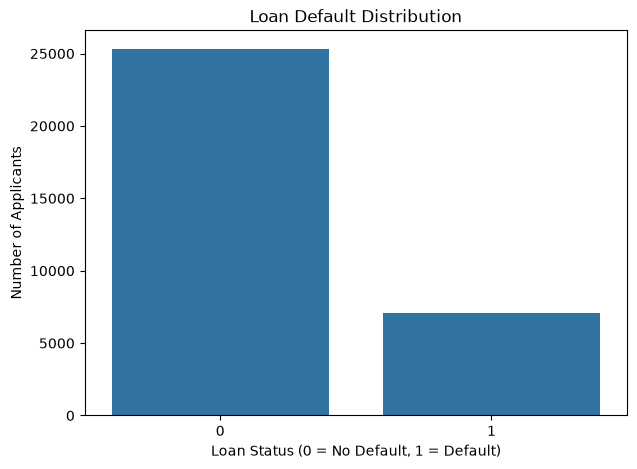

In [39]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x="loan_status"
)

plt.title("Loan Default Distribution")
plt.xlabel("Loan Status (0 = No Default, 1 = Default)")
plt.ylabel("Number of Applicants")

plt.show()

In [40]:
target_distribution = (
    df_clean["loan_status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(target_distribution)

loan_status
0    78.13
1    21.87
Name: proportion, dtype: float64


**Observation:**

The target variable is imbalanced, with a substantially larger proportion of non-defaulting applicants than defaulting applicants. Therefore, accuracy alone will not be sufficient for evaluating the classification models. Precision, recall, F1-score, ROC-AUC, and the confusion matrix will also be considered.

### 6.2 Applicant Age Distribution

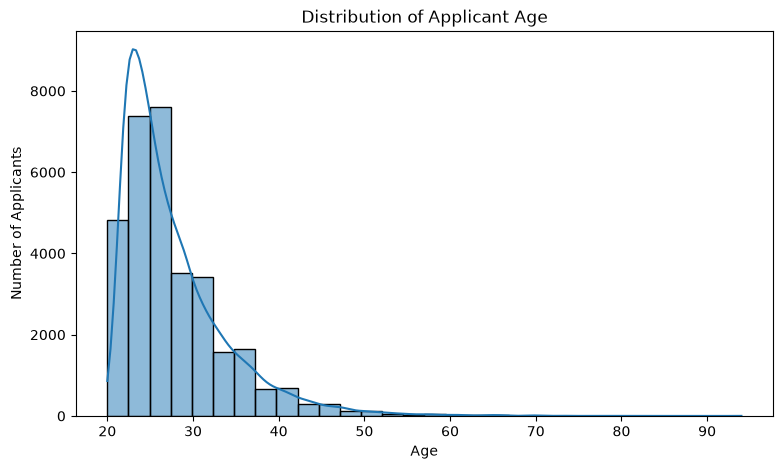

In [41]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_clean,
    x="person_age",
    bins=30,
    kde=True
)

plt.title("Distribution of Applicant Age")
plt.xlabel("Age")
plt.ylabel("Number of Applicants")

plt.show()

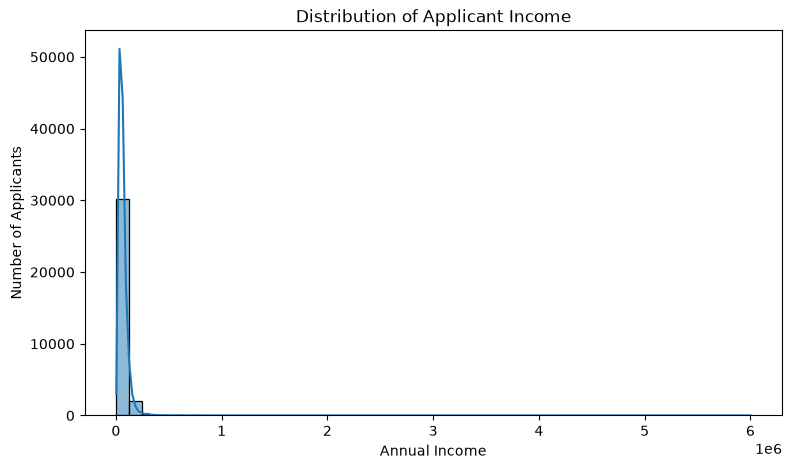

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_clean,
    x="person_income",
    bins=50,
    kde=True
)

plt.title("Distribution of Applicant Income")
plt.xlabel("Annual Income")
plt.ylabel("Number of Applicants")

plt.show()

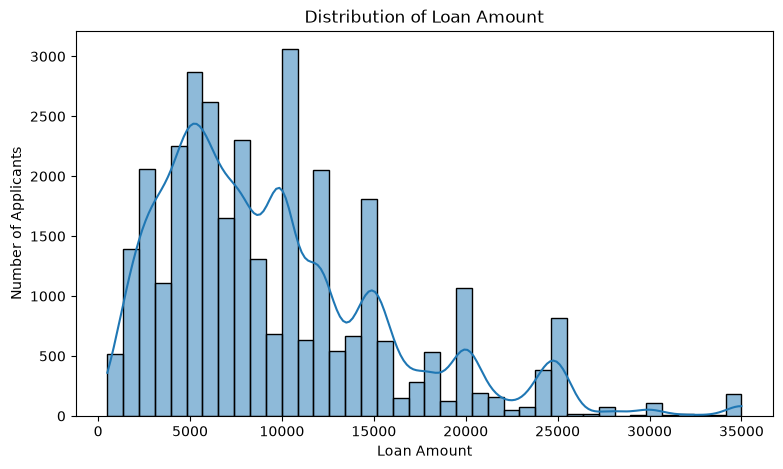

In [43]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_clean,
    x="loan_amnt",
    bins=40,
    kde=True
)

plt.title("Distribution of Loan Amount")
plt.xlabel("Loan Amount")
plt.ylabel("Number of Applicants")

plt.show()

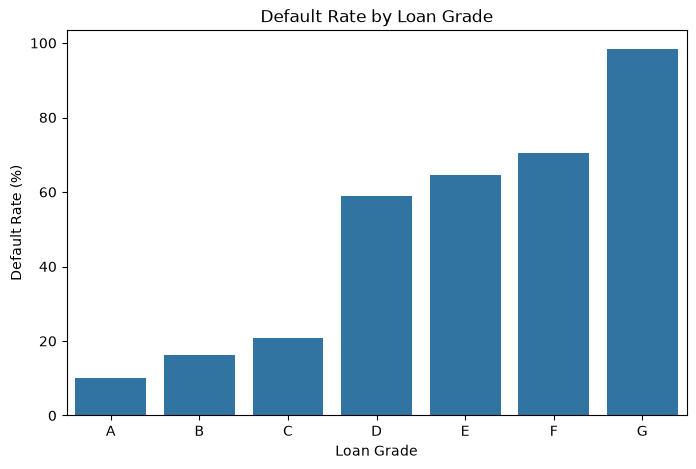

In [44]:
grade_default = (
    df_clean.groupby("loan_grade")["loan_status"]
    .mean()
    .mul(100)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=grade_default.index,
    y=grade_default.values
)

plt.title("Default Rate by Loan Grade")
plt.xlabel("Loan Grade")
plt.ylabel("Default Rate (%)")

plt.show()

In [45]:
print(grade_default.round(2))


loan_grade
A     9.96
B    16.32
C    20.75
D    59.06
E    64.49
F    70.54
G    98.44
Name: loan_status, dtype: float64


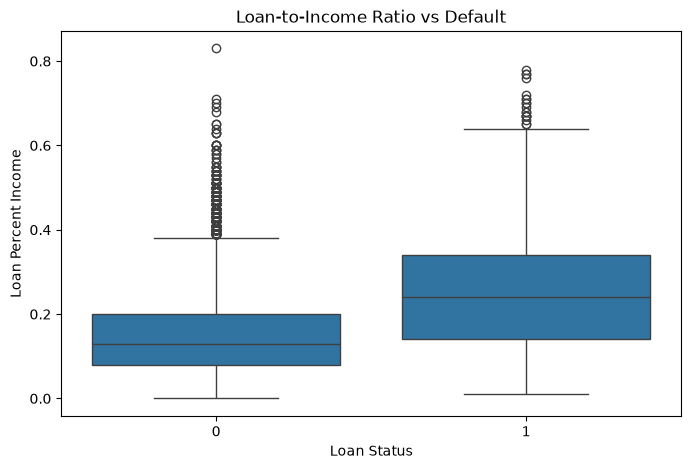

In [46]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="loan_status",
    y="loan_percent_income"
)

plt.title("Loan-to-Income Ratio vs Default")
plt.xlabel("Loan Status")
plt.ylabel("Loan Percent Income")

plt.show()

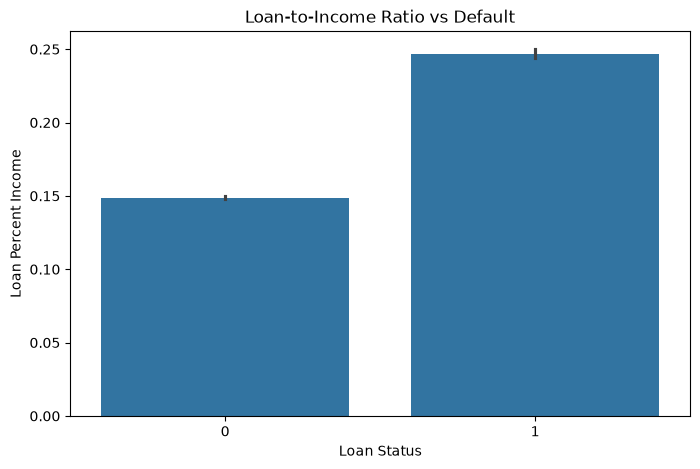

In [47]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_clean,
    x="loan_status",
    y="loan_percent_income"
)

plt.title("Loan-to-Income Ratio vs Default")
plt.xlabel("Loan Status")
plt.ylabel("Loan Percent Income")

plt.show()

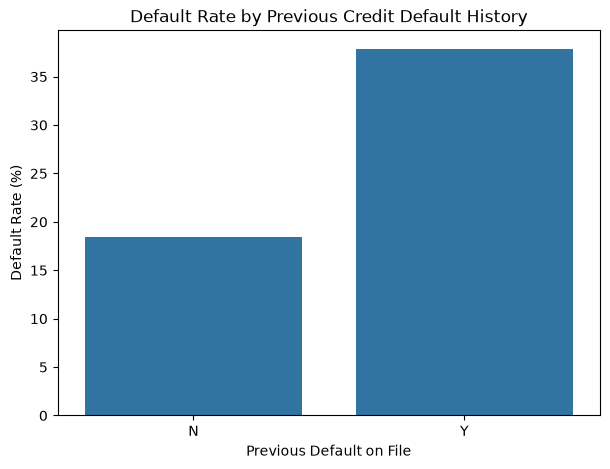

In [48]:
previous_default = (
    df_clean.groupby("cb_person_default_on_file")["loan_status"]
    .mean()
    .mul(100)
)

plt.figure(figsize=(7, 5))

sns.barplot(
    x=previous_default.index,
    y=previous_default.values
)

plt.title("Default Rate by Previous Credit Default History")
plt.xlabel("Previous Default on File")
plt.ylabel("Default Rate (%)")

plt.show()

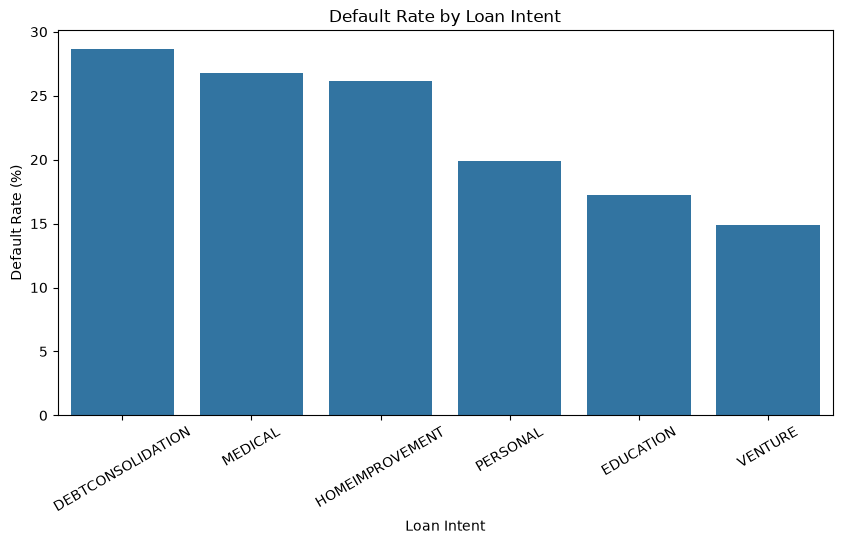

In [49]:
intent_default = (
    df_clean.groupby("loan_intent")["loan_status"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=intent_default.index,
    y=intent_default.values
)

plt.title("Default Rate by Loan Intent")
plt.xlabel("Loan Intent")
plt.ylabel("Default Rate (%)")

plt.xticks(rotation=30)

plt.show()

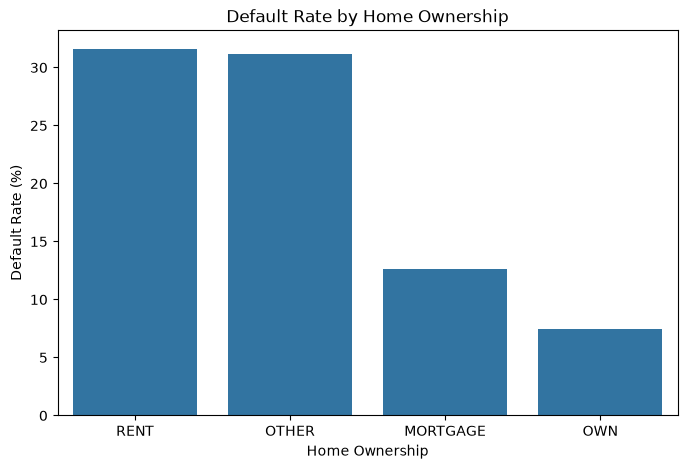

In [50]:
home_default = (
    df_clean.groupby("person_home_ownership")["loan_status"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=home_default.index,
    y=home_default.values
)

plt.title("Default Rate by Home Ownership")
plt.xlabel("Home Ownership")
plt.ylabel("Default Rate (%)")

plt.show()

In [51]:
FIGURE_DIR = Path("../reports/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Figure directory ready:", FIGURE_DIR.resolve())

Figure directory ready: C:\Users\ompis\OneDrive\Desktop\credit risk scoring model\reports\figures


In [52]:
from pathlib import Path

FIGURE_DIR = Path("../reports/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Figure directory ready:", FIGURE_DIR.resolve())

Figure directory ready: C:\Users\ompis\OneDrive\Desktop\credit risk scoring model\reports\figures


## 7. Feature Engineering and Preprocessing

In [53]:
# Separate features and target

X = df_clean.drop("loan_status", axis=1)
y = df_clean["loan_status"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (32416, 11)
Target shape: (32416,)


In [54]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']

Categorical features:
['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']


In [55]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [56]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler


In [57]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 25932
Testing samples: 6484


In [58]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

In [59]:
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

In [60]:
class_distribution = y_train.value_counts()

print(class_distribution)

print("\nPercentage:")
print(
    y_train.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

loan_status
0    20261
1     5671
Name: count, dtype: int64

Percentage:
loan_status
0    78.13
1    21.87
Name: proportion, dtype: float64


In [61]:
class_distribution = y_train.value_counts()

print(class_distribution)

print("\nPercentage:")
print(
    y_train.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

loan_status
0    20261
1     5671
Name: count, dtype: int64

Percentage:
loan_status
0    78.13
1    21.87
Name: proportion, dtype: float64


In [62]:
# Separate features and target

X = df_clean.drop("loan_status", axis=1)
y = df_clean["loan_status"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (32416, 11)
Target shape: (32416,)


In [63]:
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

In [64]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [65]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

print("Model libraries imported successfully!")

Model libraries imported successfully!


In [66]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [67]:
decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            DecisionTreeClassifier(
                max_depth=8,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

decision_tree_model.fit(X_train, y_train)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [68]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=10,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

random_forest_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [69]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=10,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

random_forest_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [70]:
gradient_boosting_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            GradientBoostingClassifier(
                n_estimators=150,
                learning_rate=0.05,
                max_depth=3,
                random_state=42
            )
        )
    ]
)

gradient_boosting_model.fit(X_train, y_train)

print("Gradient Boosting trained successfully!")

Gradient Boosting trained successfully!


In [71]:
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model
}

print("Models ready for evaluation:")
for name in models:
    print("-", name)

Models ready for evaluation:
- Logistic Regression
- Decision Tree
- Random Forest
- Gradient Boosting


In [72]:
predictions = {}
probabilities = {}

for name, model in models.items():
    predictions[name] = model.predict(X_test)
    probabilities[name] = model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully!")

Predictions generated successfully!


In [73]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = []

for name in models:
    y_pred = predictions[name]
    y_prob = probabilities[name]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.814621,0.554822,0.770804,0.645218,0.869596
1,Decision Tree,0.918415,0.894410,0.710860,0.792141,0.903994
2,Random Forest,0.909469,0.813585,0.760226,0.786001,0.922965
3,Gradient Boosting,0.927822,0.950664,0.706629,0.810680,0.921547


In [74]:
from sklearn.metrics import confusion_matrix

for name in models:
    cm = confusion_matrix(y_test, predictions[name])

    print(f"\n{name}")
    print(cm)


Logistic Regression
[[4189  877]
 [ 325 1093]]

Decision Tree
[[4947  119]
 [ 410 1008]]

Random Forest
[[4819  247]
 [ 340 1078]]

Gradient Boosting
[[5014   52]
 [ 416 1002]]


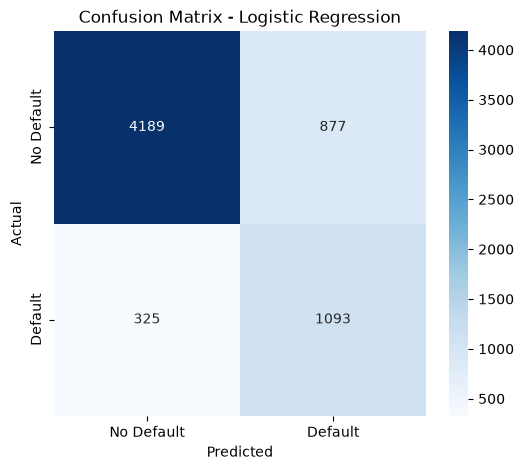

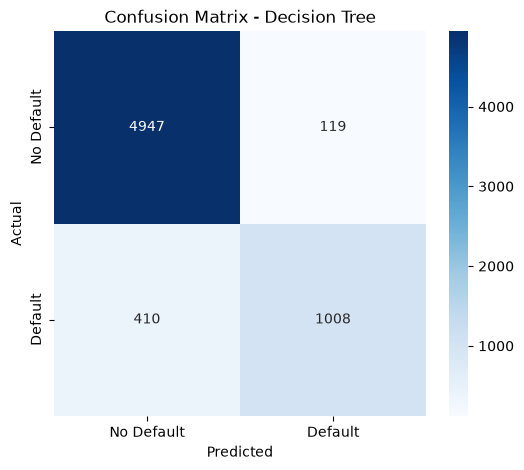

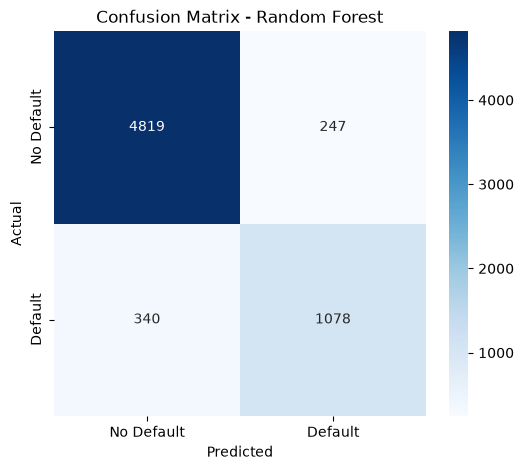

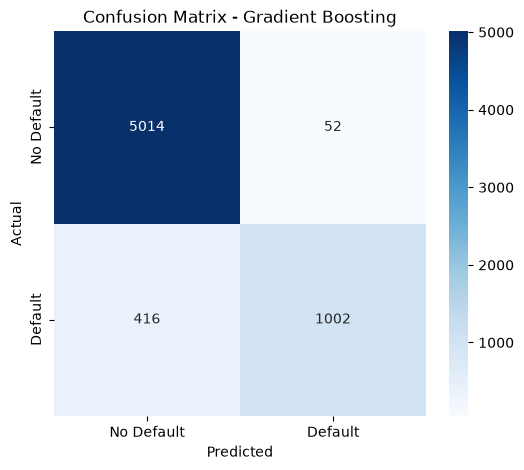

In [75]:
import matplotlib.pyplot as plt
import seaborn as sns

for name in models:
    cm = confusion_matrix(y_test, predictions[name])

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Default", "Default"],
        yticklabels=["No Default", "Default"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.show()

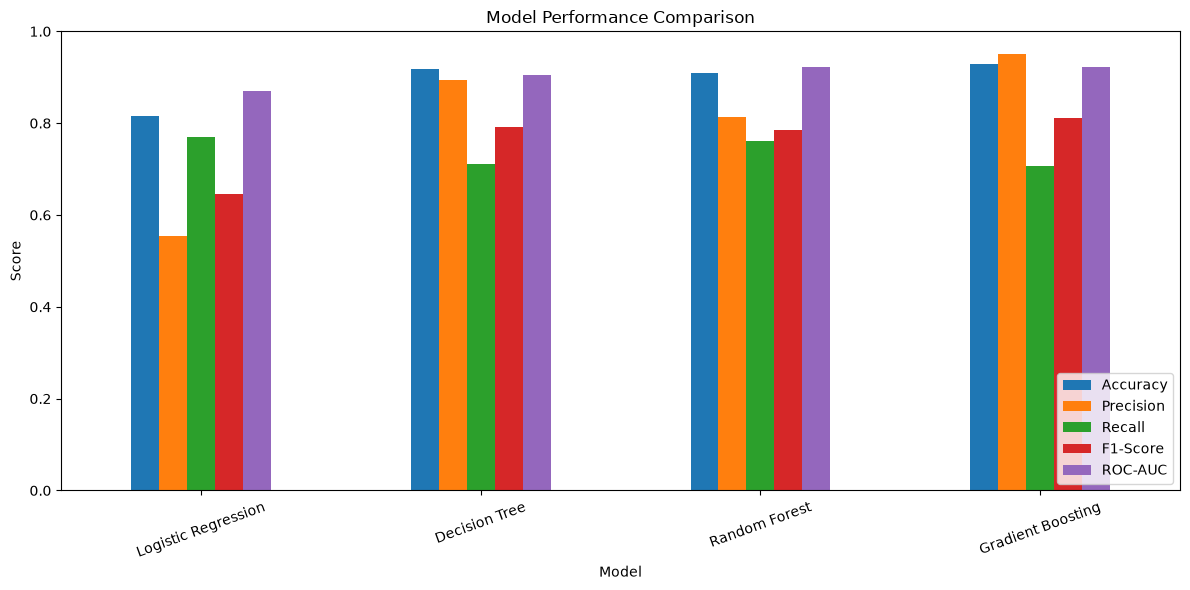

In [76]:
metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

results_df.set_index("Model")[metrics_to_plot].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [77]:
for name in models:
    cm = confusion_matrix(y_test, predictions[name])

    tn, fp, fn, tp = cm.ravel()

    print(f"\n{name}")
    print("True Negatives :", tn)
    print("False Positives:", fp)
    print("False Negatives:", fn)
    print("True Positives :", tp)


Logistic Regression
True Negatives : 4189
False Positives: 877
False Negatives: 325
True Positives : 1093

Decision Tree
True Negatives : 4947
False Positives: 119
False Negatives: 410
True Positives : 1008

Random Forest
True Negatives : 4819
False Positives: 247
False Negatives: 340
True Positives : 1078

Gradient Boosting
True Negatives : 5014
False Positives: 52
False Negatives: 416
True Positives : 1002


In [78]:
for name, model in models.items():
    train_score = model.score(X_train, y_train)
    test_score = model.score(X_test, y_test)

    print(f"\n{name}")
    print("Training Accuracy:", round(train_score, 4))
    print("Testing Accuracy :", round(test_score, 4))
    print("Difference       :", round(train_score - test_score, 4))


Logistic Regression
Training Accuracy: 0.8107
Testing Accuracy : 0.8146
Difference       : -0.0039

Decision Tree
Training Accuracy: 0.9256
Testing Accuracy : 0.9184
Difference       : 0.0072

Random Forest
Training Accuracy: 0.9242
Testing Accuracy : 0.9095
Difference       : 0.0148

Gradient Boosting
Training Accuracy: 0.9257
Testing Accuracy : 0.9278
Difference       : -0.0021


In [79]:
from sklearn.model_selection import GridSearchCV

In [80]:
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [8, 12, None],
    "classifier__min_samples_split": [2, 5]
}

In [82]:
from sklearn.model_selection import GridSearchCV

rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [8, 12, None],
    "classifier__min_samples_split": [2, 5]
}

print("Random Forest tuning setup completed!")

Random Forest tuning setup completed!


In [83]:
grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation F1-score:")
print(round(grid_search.best_score_, 4))

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best parameters:
{'classifier__max_depth': None, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}

Best cross-validation F1-score:
0.8108


In [84]:
best_rf_model = grid_search.best_estimator_

print("Best Random Forest model selected successfully!")

Best Random Forest model selected successfully!


In [85]:
tuned_rf_pred = best_rf_model.predict(X_test)
tuned_rf_prob = best_rf_model.predict_proba(X_test)[:, 1]

print("Tuned Random Forest predictions generated!")

Tuned Random Forest predictions generated!


In [86]:
tuned_rf_accuracy = accuracy_score(y_test, tuned_rf_pred)
tuned_rf_precision = precision_score(y_test, tuned_rf_pred)
tuned_rf_recall = recall_score(y_test, tuned_rf_pred)
tuned_rf_f1 = f1_score(y_test, tuned_rf_pred)
tuned_rf_roc_auc = roc_auc_score(y_test, tuned_rf_prob)

print("Tuned Random Forest Performance")
print("--------------------------------")
print("Accuracy :", round(tuned_rf_accuracy, 4))
print("Precision:", round(tuned_rf_precision, 4))
print("Recall   :", round(tuned_rf_recall, 4))
print("F1-Score :", round(tuned_rf_f1, 4))
print("ROC-AUC  :", round(tuned_rf_roc_auc, 4))

Tuned Random Forest Performance
--------------------------------
Accuracy : 0.9274
Precision: 0.9078
Recall   : 0.7433
F1-Score : 0.8174
ROC-AUC  : 0.9289


In [87]:
tuned_cm = confusion_matrix(y_test, tuned_rf_pred)

tn, fp, fn, tp = tuned_cm.ravel()

print("Tuned Random Forest Confusion Matrix")
print("------------------------------------")
print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)

Tuned Random Forest Confusion Matrix
------------------------------------
True Negatives : 4959
False Positives: 107
False Negatives: 364
True Positives : 1054


In [88]:
original_rf_metrics = {
    "Accuracy": accuracy_score(y_test, predictions["Random Forest"]),
    "Precision": precision_score(y_test, predictions["Random Forest"]),
    "Recall": recall_score(y_test, predictions["Random Forest"]),
    "F1-Score": f1_score(y_test, predictions["Random Forest"]),
    "ROC-AUC": roc_auc_score(y_test, probabilities["Random Forest"])
}

tuned_rf_metrics = {
    "Accuracy": tuned_rf_accuracy,
    "Precision": tuned_rf_precision,
    "Recall": tuned_rf_recall,
    "F1-Score": tuned_rf_f1,
    "ROC-AUC": tuned_rf_roc_auc
}

comparison_df = pd.DataFrame({
    "Original Random Forest": original_rf_metrics,
    "Tuned Random Forest": tuned_rf_metrics
})

comparison_df

,Original Random Forest,Tuned Random Forest
Accuracy,0.909469,0.927360
Precision,0.813585,0.907838
Recall,0.760226,0.743300
F1-Score,0.786001,0.817371
ROC-AUC,0.922965,0.928905


In [89]:
print("grid_search exists:", "grid_search" in globals())
print("best_rf_model exists:", "best_rf_model" in globals())

grid_search exists: True
best_rf_model exists: True


In [90]:
print("grid_search exists:", "grid_search" in globals())
print("best_rf_model exists:", "best_rf_model" in globals())

grid_search exists: True
best_rf_model exists: True


In [91]:
from sklearn.model_selection import GridSearchCV

In [92]:
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [8, 12, None],
    "classifier__min_samples_split": [2, 5]
}

print("Random Forest tuning setup completed!")

Random Forest tuning setup completed!


In [93]:
grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation F1-score:")
print(round(grid_search.best_score_, 4))

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best parameters:
{'classifier__max_depth': None, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}

Best cross-validation F1-score:
0.8108


In [94]:
best_rf_model = grid_search.best_estimator_

print("Best Random Forest model selected successfully!")

Best Random Forest model selected successfully!


In [95]:
print("grid_search exists:", "grid_search" in globals())
print("best_rf_model exists:", "best_rf_model" in globals())

grid_search exists: True
best_rf_model exists: True


In [96]:
rf_classifier = best_rf_model.named_steps["classifier"]

feature_names = best_rf_model.named_steps[
    "preprocessor"
].get_feature_names_out()

importance_values = rf_classifier.feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

feature_importance_df.head(15)

,Feature,Importance
5,num__loan_percent_income,0.198473
1,num__person_income,0.159439
4,num__loan_int_rate,0.126900
3,num__loan_amnt,0.080409
20,cat__loan_grade_D,0.055260
2,num__person_emp_length,0.054751
0,num__person_age,0.049600
10,cat__person_home_ownership_RENT,0.042032
6,num__cb_person_cred_hist_length,0.038870
17,cat__loan_grade_A,0.022491


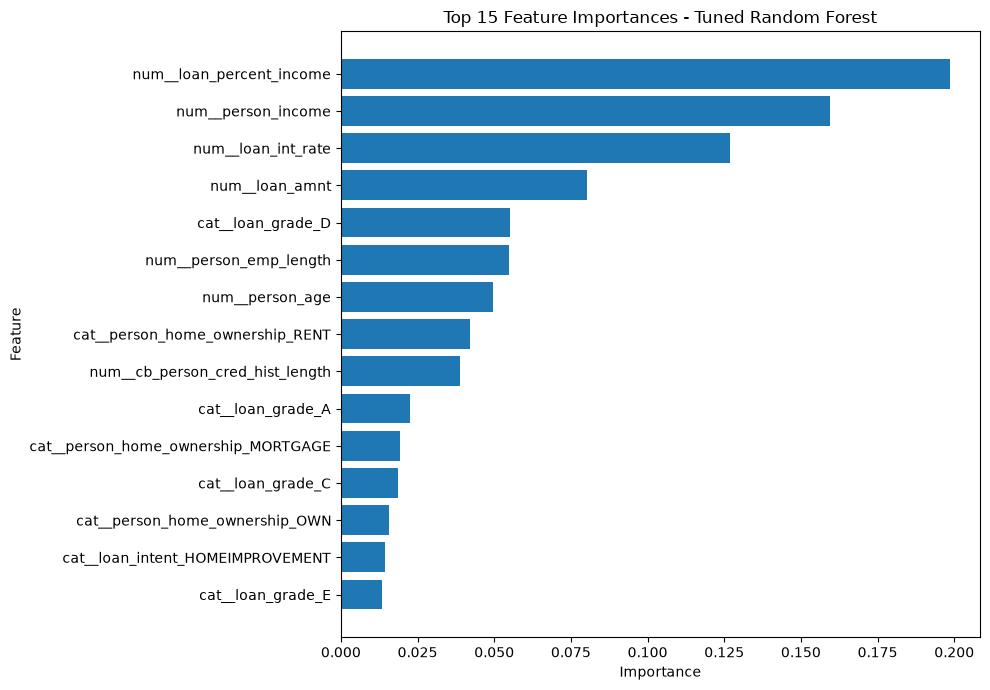

In [97]:
top_features = feature_importance_df.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.title("Top 15 Feature Importances - Tuned Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [98]:
try:
    import shap
    print("SHAP is installed successfully!")
except ImportError:
    print("SHAP is not installed.")

SHAP is installed successfully!


In [99]:
print("SHAP version:", shap.__version__)

SHAP version: 0.52.0


In [100]:
# Define the target column
target_column = "loan_status"

print("Target column:", target_column)

print("\nTarget in X columns:")
print(target_column in X.columns)

print("\nNumber of input features:", X.shape[1])

Target column: loan_status

Target in X columns:
False

Number of input features: 11


In [101]:
# Final model comparison table

final_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting",
        "Tuned Random Forest"
    ],
    "Accuracy": [
        0.8146,
        0.9184,
        0.9095,
        0.9278,
        0.9274
    ],
    "Precision": [
        0.556,
        0.894,
        0.814,
        0.950,
        0.9078
    ],
    "Recall": [
        0.771,
        0.711,
        0.760,
        0.706,
        0.7433
    ],
    "F1-Score": [
        0.645,
        0.792,
        0.786,
        0.808,
        0.8174
    ],
    "ROC-AUC": [
        0.868,
        0.900,
        0.920,
        0.921,
        0.9289
    ]
})

final_comparison

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8146,0.5560,0.7710,0.6450,0.8680
1,Decision Tree,0.9184,0.8940,0.7110,0.7920,0.9000
2,Random Forest,0.9095,0.8140,0.7600,0.7860,0.9200
3,Gradient Boosting,0.9278,0.9500,0.7060,0.8080,0.9210
4,Tuned Random Forest,0.9274,0.9078,0.7433,0.8174,0.9289


In [102]:
final_comparison["False Negatives"] = [
    325,
    410,
    340,
    416,
    364
]

final_comparison

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,False Negatives
0,Logistic Regression,0.8146,0.5560,0.7710,0.6450,0.8680,325
1,Decision Tree,0.9184,0.8940,0.7110,0.7920,0.9000,410
2,Random Forest,0.9095,0.8140,0.7600,0.7860,0.9200,340
3,Gradient Boosting,0.9278,0.9500,0.7060,0.8080,0.9210,416
4,Tuned Random Forest,0.9274,0.9078,0.7433,0.8174,0.9289,364


In [103]:
final_model = best_rf_model

print("Final model pipeline assigned successfully.")

Final model pipeline assigned successfully.


In [104]:
# Predicted probability of the positive/default class

risk_probability = final_model.predict_proba(X_test)[:, 1]

print("First 10 risk probabilities:")
print(risk_probability[:10])

First 10 risk probabilities:
[0.57 0.17 0.02 0.04 1.   0.1  0.96 0.27 0.11 0.07]


In [105]:
risk_score = risk_probability * 100

print("First 10 risk scores:")
print(risk_score[:10])

First 10 risk scores:
[ 57.  17.   2.   4. 100.  10.  96.  27.  11.   7.]


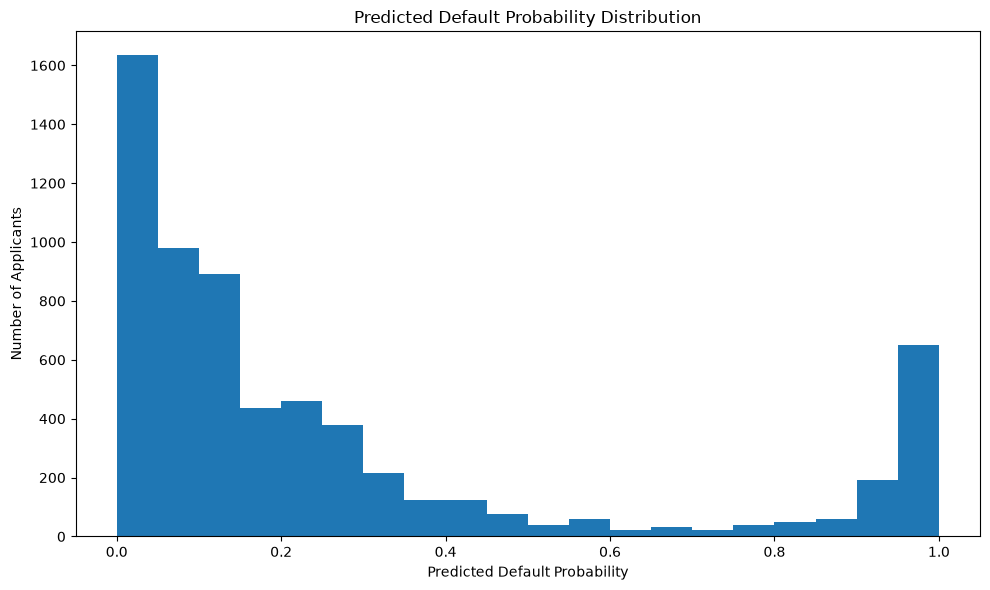

In [106]:
plt.figure(figsize=(10, 6))

plt.hist(risk_probability, bins=20)

plt.title("Predicted Default Probability Distribution")
plt.xlabel("Predicted Default Probability")
plt.ylabel("Number of Applicants")

plt.tight_layout()
plt.show()

In [107]:
import numpy as np

p25 = np.percentile(risk_probability, 25)
p50 = np.percentile(risk_probability, 50)
p75 = np.percentile(risk_probability, 75)

print("25th percentile:", round(p25, 4))
print("50th percentile:", round(p50, 4))
print("75th percentile:", round(p75, 4))

25th percentile: 0.04
50th percentile: 0.13
75th percentile: 0.32


In [108]:
def assign_risk_category(probability):
    if probability <= p25:
        return "Low"
    elif probability <= p75:
        return "Medium"
    else:
        return "High"

In [109]:
risk_category = np.array([
    assign_risk_category(p)
    for p in risk_probability
])

print(risk_category[:20])

['High' 'Medium' 'Low' 'Low' 'High' 'Medium' 'High' 'Medium' 'Medium'
 'Medium' 'Low' 'High' 'Medium' 'Medium' 'Low' 'Medium' 'Medium' 'Low'
 'High' 'Medium']


In [110]:
risk_results = pd.DataFrame({
    "Risk Probability": risk_probability,
    "Risk Score": risk_score,
    "Risk Category": risk_category
})

risk_results.head(10)

,Risk Probability,Risk Score,Risk Category
0,0.57,57.0,High
1,0.17,17.0,Medium
2,0.02,2.0,Low
3,0.04,4.0,Low
4,1.00,100.0,High
5,0.10,10.0,Medium
6,0.96,96.0,High
7,0.27,27.0,Medium
8,0.11,11.0,Medium
9,0.07,7.0,Medium


In [111]:
risk_results["Risk Category"].value_counts()

Risk Category
Medium    3241
Low       1634
High      1609
Name: count, dtype: int64

In [112]:
risk_results["Risk Category"].value_counts(normalize=True).mul(100).round(2)

Risk Category
Medium    49.98
Low       25.20
High      24.81
Name: proportion, dtype: float64

In [113]:
print("grid_search exists:", "grid_search" in globals())
print("X_train exists:", "X_train" in globals())
print("X_test exists:", "X_test" in globals())

grid_search exists: True
X_train exists: True
X_test exists: True


In [114]:
print("grid_search exists:", "grid_search" in globals())
print("X_train exists:", "X_train" in globals())
print("X_test exists:", "X_test" in globals())
print("best_rf_model exists:", "best_rf_model" in globals())

grid_search exists: True
X_train exists: True
X_test exists: True
best_rf_model exists: True


In [115]:
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [8, 12, None],
    "classifier__min_samples_split": [2, 5]
}

print("Random Forest tuning setup restored!")

Random Forest tuning setup restored!


In [116]:
from sklearn.model_selection import GridSearchCV

print("GridSearchCV imported successfully!")

GridSearchCV imported successfully!


In [117]:
grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("\nBest parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation F1-score:")
print(round(grid_search.best_score_, 4))

Fitting 3 folds for each of 12 candidates, totalling 36 fits

Best parameters:
{'classifier__max_depth': None, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}

Best cross-validation F1-score:
0.8108


In [118]:
# Create the tuned Random Forest pipeline using the best parameters

best_rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=100,
                max_depth=None,
                min_samples_split=2,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Tuned Random Forest pipeline created successfully!")

Tuned Random Forest pipeline created successfully!


In [119]:
# Train the tuned Random Forest

best_rf_model.fit(X_train, y_train)

print("Tuned Random Forest trained successfully!")

Tuned Random Forest trained successfully!


In [120]:
final_model = best_rf_model

print("Final model ready!")

Final model ready!


In [121]:
risk_probability = final_model.predict_proba(X_test)[:, 1]

print("First 10 risk probabilities:")
print(risk_probability[:10])

First 10 risk probabilities:
[0.57 0.17 0.02 0.04 1.   0.1  0.96 0.27 0.11 0.07]


In [122]:
risk_score = risk_probability * 100

print("First 10 risk scores:")
print(risk_score[:10])

First 10 risk scores:
[ 57.  17.   2.   4. 100.  10.  96.  27.  11.   7.]


In [123]:
risk_score = risk_probability * 100

print("First 10 risk scores:")
print(risk_score[:10])

First 10 risk scores:
[ 57.  17.   2.   4. 100.  10.  96.  27.  11.   7.]


In [124]:
print("p25:", "p25" in globals())
print("p75:", "p75" in globals())
print("assign_risk_category:", "assign_risk_category" in globals())

p25: True
p75: True
assign_risk_category: True


In [125]:
risk_category = np.array([
    assign_risk_category(p)
    for p in risk_probability
])

print("First 10 risk categories:")
print(risk_category[:10])

First 10 risk categories:
['High' 'Medium' 'Low' 'Low' 'High' 'Medium' 'High' 'Medium' 'Medium'
 'Medium']


In [126]:
risk_validation = pd.DataFrame({
    "Actual_Default": y_test.values,
    "Risk_Probability": risk_probability,
    "Risk_Score": risk_score,
    "Risk_Category": risk_category
})

risk_validation.head(10)

,Actual_Default,Risk_Probability,Risk_Score,Risk_Category
0,0,0.57,57.0,High
1,1,0.17,17.0,Medium
2,0,0.02,2.0,Low
3,0,0.04,4.0,Low
4,1,1.00,100.0,High
5,0,0.10,10.0,Medium
6,1,0.96,96.0,High
7,0,0.27,27.0,Medium
8,0,0.11,11.0,Medium
9,0,0.07,7.0,Medium


In [127]:
default_rate_by_category = (
    risk_validation
    .groupby("Risk_Category")["Actual_Default"]
    .mean()
    .mul(100)
    .round(2)
)

print("Actual Default Rate by Risk Category:")
print(default_rate_by_category)

Actual Default Rate by Risk Category:
Risk_Category
High      71.29
Low        1.35
Medium     7.68
Name: Actual_Default, dtype: float64


In [128]:
try:
    import shap
    print("SHAP is installed successfully!")
    print("SHAP version:", shap.__version__)
except ImportError:
    print("SHAP is not installed.")

SHAP is installed successfully!
SHAP version: 0.52.0


In [129]:
import shap

# Get the trained Random Forest classifier
rf_classifier = final_model.named_steps["classifier"]

# Get the preprocessing pipeline
preprocessor_fitted = final_model.named_steps["preprocessor"]

# Transform the test data
X_test_transformed = preprocessor_fitted.transform(X_test)

print("Test data transformed successfully!")
print("Transformed shape:", X_test_transformed.shape)

Test data transformed successfully!
Transformed shape: (6484, 26)


In [130]:
feature_names = preprocessor_fitted.get_feature_names_out()

print("Number of features:", len(feature_names))
print("\nFirst 20 feature names:")
print(feature_names[:20])

Number of features: 26

First 20 feature names:
['num__person_age' 'num__person_income' 'num__person_emp_length'
 'num__loan_amnt' 'num__loan_int_rate' 'num__loan_percent_income'
 'num__cb_person_cred_hist_length' 'cat__person_home_ownership_MORTGAGE'
 'cat__person_home_ownership_OTHER' 'cat__person_home_ownership_OWN'
 'cat__person_home_ownership_RENT' 'cat__loan_intent_DEBTCONSOLIDATION'
 'cat__loan_intent_EDUCATION' 'cat__loan_intent_HOMEIMPROVEMENT'
 'cat__loan_intent_MEDICAL' 'cat__loan_intent_PERSONAL'
 'cat__loan_intent_VENTURE' 'cat__loan_grade_A' 'cat__loan_grade_B'
 'cat__loan_grade_C']


In [131]:
# Use a smaller sample for SHAP analysis
X_shap = X_test_transformed[:1000]

explainer = shap.TreeExplainer(rf_classifier)

shap_values = explainer.shap_values(X_shap)

print("SHAP calculation completed!")

SHAP calculation completed!


In [132]:
# Handle different SHAP output formats

if isinstance(shap_values, list):
    shap_for_positive_class = shap_values[1]
else:
    if len(shap_values.shape) == 3:
        shap_for_positive_class = shap_values[:, :, 1]
    else:
        shap_for_positive_class = shap_values

mean_abs_shap = np.abs(shap_for_positive_class).mean(axis=0)

shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Absolute_SHAP": mean_abs_shap
})

shap_importance = shap_importance.sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
)

shap_importance.head(15)

,Feature,Mean_Absolute_SHAP
5,num__loan_percent_income,0.117873
1,num__person_income,0.070021
4,num__loan_int_rate,0.060235
10,cat__person_home_ownership_RENT,0.053789
20,cat__loan_grade_D,0.045906
17,cat__loan_grade_A,0.041390
16,cat__loan_intent_VENTURE,0.022025
19,cat__loan_grade_C,0.021716
3,num__loan_amnt,0.020240
9,cat__person_home_ownership_OWN,0.019076


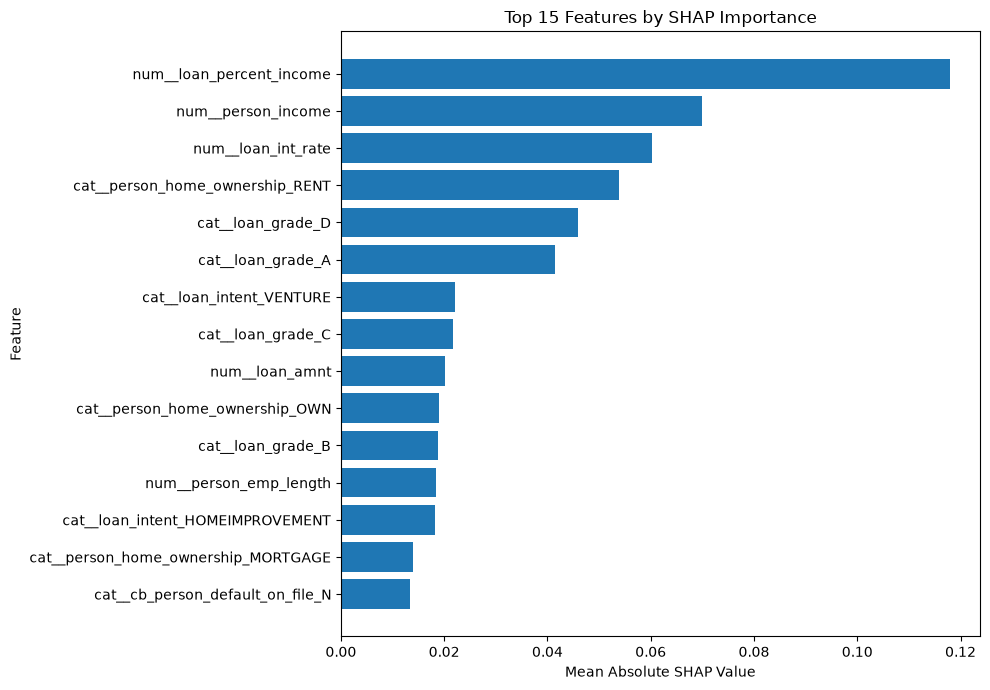

In [133]:
top_shap = shap_importance.head(15).sort_values(
    "Mean_Absolute_SHAP"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_shap["Feature"],
    top_shap["Mean_Absolute_SHAP"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("Top 15 Features by SHAP Importance")

plt.tight_layout()
plt.show()

In [134]:
print(df_clean.columns.tolist())

['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length']


In [135]:
def predict_credit_risk(
    person_age,
    person_income,
    person_home_ownership,
    person_emp_length,
    loan_intent,
    loan_grade,
    loan_amnt,
    loan_int_rate,
    loan_percent_income,
    cb_person_default_on_file,
    cb_person_cred_hist_length
):
    
    # Create applicant data
    applicant = pd.DataFrame([{
        "person_age": person_age,
        "person_income": person_income,
        "person_home_ownership": person_home_ownership,
        "person_emp_length": person_emp_length,
        "loan_intent": loan_intent,
        "loan_grade": loan_grade,
        "loan_amnt": loan_amnt,
        "loan_int_rate": loan_int_rate,
        "loan_percent_income": loan_percent_income,
        "cb_person_default_on_file": cb_person_default_on_file,
        "cb_person_cred_hist_length": cb_person_cred_hist_length
    }])
    
    # Predict probability of default
    probability = final_model.predict_proba(applicant)[0, 1]
    
    # Convert probability to 0-100 risk score
    score = probability * 100
    
    # Determine risk category
    category = assign_risk_category(probability)
    
    return {
        "Predicted Risk": category,
        "Risk Probability": round(probability * 100, 2),
        "Risk Score": round(score, 2)
    }

In [136]:
sample_result = predict_credit_risk(
    person_age=30,
    person_income=50000,
    person_home_ownership="RENT",
    person_emp_length=5,
    loan_intent="PERSONAL",
    loan_grade="B",
    loan_amnt=10000,
    loan_int_rate=10.5,
    loan_percent_income=0.20,
    cb_person_default_on_file="N",
    cb_person_cred_hist_length=5
)

print(sample_result)

{'Predicted Risk': 'Low', 'Risk Probability': np.float64(2.0), 'Risk Score': np.float64(2.0)}


In [137]:
applicant_1 = predict_credit_risk(
    30, 80000, "OWN", 7, "EDUCATION", "A",
    8000, 8.5, 0.10, "N", 8
)

print("Applicant 1:")
print(applicant_1)

Applicant 1:
{'Predicted Risk': 'Medium', 'Risk Probability': np.float64(5.0), 'Risk Score': np.float64(5.0)}


In [138]:
applicant_1 = predict_credit_risk(
    30, 80000, "OWN", 7, "EDUCATION", "A",
    8000, 8.5, 0.10, "N", 8
)

print("Applicant 1:")
print(applicant_1)

Applicant 1:
{'Predicted Risk': 'Medium', 'Risk Probability': np.float64(5.0), 'Risk Score': np.float64(5.0)}


In [139]:
applicant_3 = predict_credit_risk(
    25, 30000, "RENT", 2, "DEBTCONSOLIDATION", "E",
    18000, 16.5, 0.60, "Y", 3
)

print("Applicant 3:")
print(applicant_3)

Applicant 3:
{'Predicted Risk': 'High', 'Risk Probability': np.float64(99.0), 'Risk Score': np.float64(99.0)}


In [140]:
import joblib

In [141]:
MODEL_PATH = "../models/credit_risk_model.pkl"

joblib.dump(final_model, MODEL_PATH)

print("Final model saved successfully!")
print("Model path:", MODEL_PATH)

Final model saved successfully!
Model path: ../models/credit_risk_model.pkl


In [142]:
loaded_model = joblib.load(MODEL_PATH)

print("Saved model loaded successfully!")

Saved model loaded successfully!


In [143]:
test_probability = loaded_model.predict_proba(
    pd.DataFrame([{
        "person_age": 30,
        "person_income": 50000,
        "person_home_ownership": "RENT",
        "person_emp_length": 5,
        "loan_intent": "PERSONAL",
        "loan_grade": "B",
        "loan_amnt": 10000,
        "loan_int_rate": 10.5,
        "loan_percent_income": 0.20,
        "cb_person_default_on_file": "N",
        "cb_person_cred_hist_length": 5
}])
)[0, 1]

print("Loaded model probability:", round(float(test_probability * 100), 2), "%")

Loaded model probability: 2.0 %


In [144]:
p25 = np.percentile(risk_probability, 25)
p50 = np.percentile(risk_probability, 50)
p75 = np.percentile(risk_probability, 75)

print("25th percentile:", p25)
print("50th percentile:", p50)
print("75th percentile:", p75)

25th percentile: 0.04
50th percentile: 0.13
75th percentile: 0.32
